# Do cities with more police have lower crime?

For violent crimes, it seems the opposite.  If I try to do some primitive layering by demographics, the picture doesn't change much.

However, the data itself came from [AI Studio]("https://aistudio.google.com/app/prompts?state=%7B%22ids%22:%5B%2213Aoi0z4QK0uFOJS-0TLO0mZE1LFHCGhF%22%5D,%22action%22:%22open%22,%22userId%22:%22106663353829707201139%22,%22resourceKeys%22:%7B%7D%7D&usp=sharing, https://drive.google.com/file/d/1BrmAVWAzQv8vseCov3dBTzm5AS0u7BTM/view?usp=sharing"), and there was a big list of problems in the dialog.  I doubt they are all fixed, and I didn't check any of the source URLs for hallucination.

In [23]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
# I had to remove Phoenix b/c AISTUDIO kept screwing it up
df = pd.read_csv("./violent_crime.csv")
# df2 = df.copy()
#df = pd.read_excel("./violent_crime.xlsx")
df['violent crimes per 100k'] = df['violent crimes'] / df['population'] * 100000
df['police per 100k'] = df['number of police'] / df['population'] * 100000
# df2.set_index('police per 100k', inplace=True)

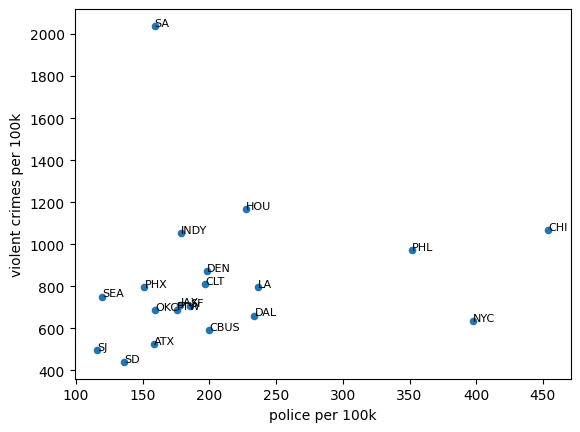

In [ ]:
def crime_police_plot(df):
    df.plot.scatter(x='police per 100k', y='violent crimes per 100k')
    for i, row in df.iterrows():
        plt.text(row['police per 100k'], row['violent crimes per 100k'], row['abbreviation'], fontsize=8)


crime_police_plot(df)

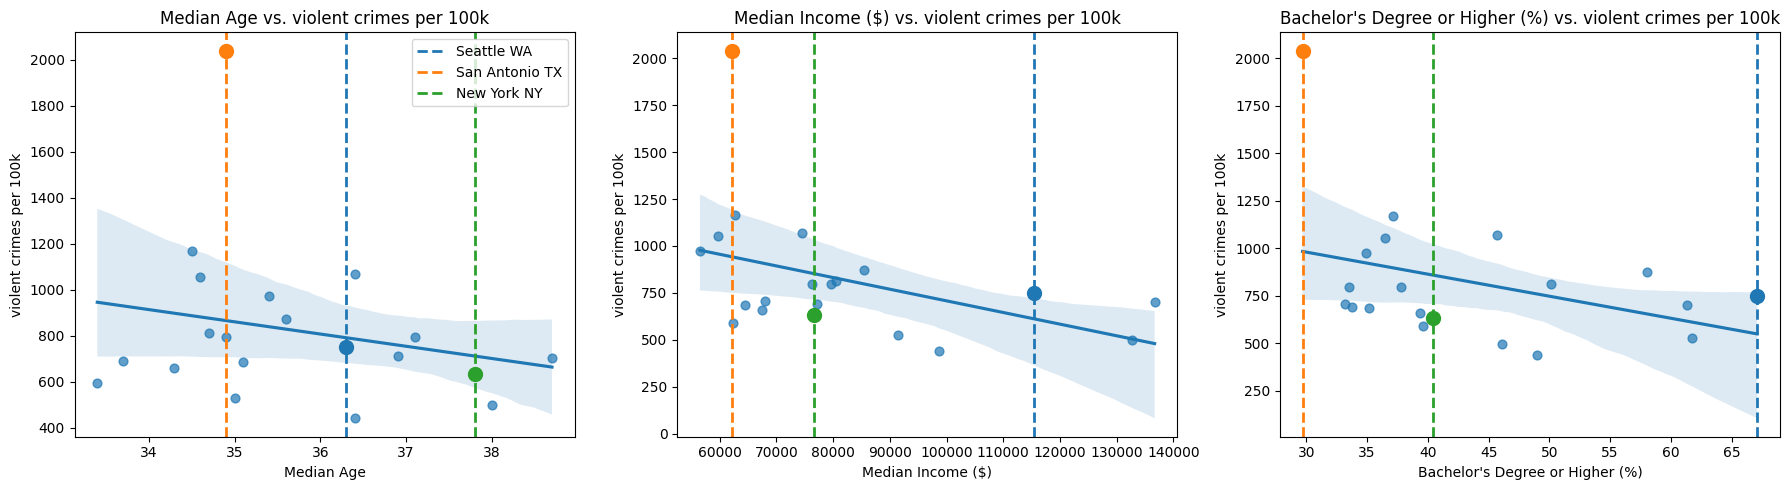

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
from icecream import ic

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
features = [
    'Median Age',
    'Median Income ($)',
    "Bachelor's Degree or Higher (%)"
]
target = "violent crimes per 100k"

highlight_cities = ['Seattle WA', 'San Antonio TX', 'New York NY']
highlight_colors = {'Seattle WA': 'tab:blue', 'San Antonio TX': 'tab:orange', 'New York NY': 'tab:green'}

for ax, feature in zip(axes, features):
    sns.regplot(data=df, x=feature, y=target, ax=ax, scatter_kws={'s': 40, 'alpha': 0.7})
    ax.set_title(f'{feature} vs. {target}')
    # Add vertical lines for each highlight city
    for city in highlight_cities:
        # Print all city names for debugging
        #print('Available cities:', list(df['city']))
        city_row = df[df['city'].str.lower().str.strip() == city.lower().strip()]
        #print(f'Looking for city: {city}, found rows: {len(city_row)}')
        if not city_row.empty:
            x_val = city_row.iloc[0][feature]
            # print(f'Plotting vertical line for {city} at {feature}={x_val}')
            # Only add label for the first subplot to avoid duplicate legend entries
            label = city if ax == axes[0] else None
            ax.axvline(x=x_val, color=highlight_colors[city], linestyle='--', linewidth=2, label=label)
            # Optionally, add a marker at the intersection
            y_val = city_row.iloc[0][target]
            ax.plot(x_val, y_val, marker='o', color=highlight_colors[city], markersize=10, label=None)
        else:
            print(f'City {city} not found in data!')
    # Only add legend to the first subplot
    if ax == axes[0]:
        handles, labels = ax.get_legend_handles_labels()
        by_label = dict(zip(labels, handles))
        ax.legend(by_label.values(), by_label.keys())

plt.tight_layout()
plt.show()

In [17]:
median_us_bachelor = 37.7
median_us_household_income = 83150
median_us_age = 39.1
df[df[ 'Median Income ($)']<median_us_household_income]
df[df[ 'Median Age']<35]
df[df[ 'Bachelor\'s Degree or Higher (%)']<median_us_bachelor]

,city,abbreviation,population,violent crimes,population data source,violent crime data source,number of police,number of police data source,Median Age,Median Age Data Source,Median Income ($),Median Income Data Source,Bachelor's Degree or Higher (%),Bachelor's Degree Data Source,violent crimes per 100k,police per 100k
3,Houston TX,HOU,2333346,27243,https://www.houstontx.gov/planning/Demographic...,https://www.houstonpolice.org/crime-statistics...,5300,https://www.houstonpolice.org/,34.5,"https://data.census.gov/profile/Houston_city,_...",62637,"https://data.census.gov/profile/Houston_city,_...",37.1,"https://data.census.gov/profile/Houston_city,_...",1167.550805,227.141624
4,Phoenix AZ,PHX,1673164,13313,https://www.census.gov/,https://www.phoenix.gov/policesite/Documents/P...,2532,https://www.yourvalley.net/phoenix-independent...,34.9,"https://data.census.gov/profile/Phoenix_city,_...",79664,"https://data.census.gov/profile/Phoenix_city,_...",33.5,"https://data.census.gov/profile/Phoenix_city,_...",795.678128,151.330055
5,Philadelphia PA,PHL,1573916,15317,https://www.census.gov/,https://www.phillypolice.com/crime-maps-stats/,5535,https://www.phila.gov/departments/philadelphia...,35.4,https://data.census.gov/profile/Philadelphia_c...,56515,https://data.census.gov/profile/Philadelphia_c...,34.9,https://data.census.gov/profile/Philadelphia_c...,973.177730,351.670610
6,San Antonio TX,SA,1526656,31126,https://www.census.gov/,https://www.kens5.com/article/news/crime/san-a...,2427,https://www.sanantonio.gov/sapd,34.9,https://data.census.gov/profile/San_Antonio_ci...,62102,https://data.census.gov/profile/San_Antonio_ci...,29.7,https://data.census.gov/profile/San_Antonio_ci...,2038.835206,158.974910
9,Jacksonville FL,JAX,1009833,7160,https://www.census.gov/,https://www.fdle.state.fl.us/CJAB/UCR/Annual-R...,1800,https://www.jaxsheriff.org/,36.9,https://data.census.gov/profile/Jacksonville_c...,68069,https://data.census.gov/profile/Jacksonville_c...,33.2,https://data.census.gov/profile/Jacksonville_c...,709.028126,178.247294
10,Fort Worth TX,FTW,1008106,6944,https://www.fortworthtexas.gov/departments/pla...,https://police.fortworthtexas.gov/crime-inform...,1768,https://police.fortworthtexas.gov/,33.7,https://data.census.gov/profile/Fort_Worth_cit...,77082,https://data.census.gov/profile/Fort_Worth_cit...,33.8,https://data.census.gov/profile/Fort_Worth_cit...,688.816454,175.378383
15,Indianapolis IN,INDY,891484,9384,https://www.census.gov/,https://www.neighborhoodscout.com/in/indianapo...,1593,https://www.indy.gov/agency/indianapolis-metro...,34.6,https://data.census.gov/profile/Indianapolis_c...,59628,https://data.census.gov/profile/Indianapolis_c...,36.5,https://data.census.gov/profile/Indianapolis_c...,1052.626856,178.690812
19,Oklahoma City OK,OKC,712919,4896,https://www.census.gov/,https://okc.gov/departments/police/crime-preve...,1135,https://okc.gov/departments/police,35.1,https://data.census.gov/profile/Oklahoma_City_...,64497,https://data.census.gov/profile/Oklahoma_City_...,35.2,https://data.census.gov/profile/Oklahoma_City_...,686.754035,159.204622


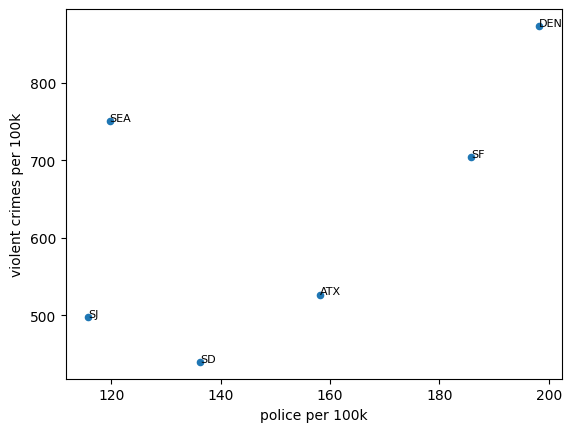

In [21]:
crime_police_plot(df[df[ 'Median Income ($)']>=median_us_household_income])
#df[df[ 'Median Income ($)']>=median_us_household_income]

In [ ]:
# all cities under median US age
# crime_police_plot(df[df[ 'Median Age']>=median_us_age])

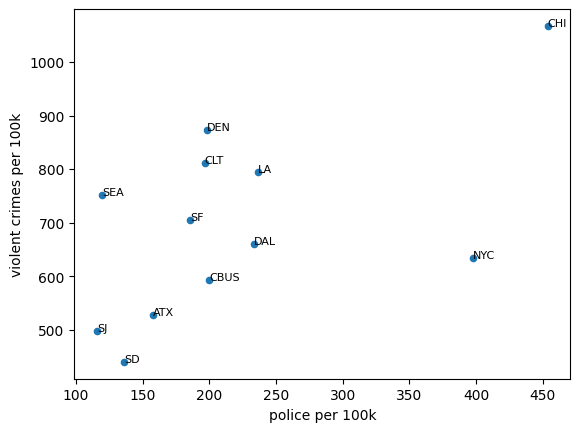

In [ ]:
crime_police_plot(df[df[ 'Bachelor\'s Degree or Higher (%)']>=median_us_bachelor])